# PA2 Q2 · Notebook 2: Baseline ConvLSTM, model A (Table 2, Figure 2)

Trains model A with seeds 0 and 1 (30 epochs each, about 10–15 min per seed on a T4), compares it with the Blank and Copy-last reference predictors (Table 2), and shows example forecasts (Figure 2).

**Kaggle settings (right-hand panel → Session options):**
- Accelerator: **GPU T4** (required: this notebook trains or evaluates models, and must not run on CPU)
- Internet: **On** (torchvision downloads Moving MNIST, about 800 MB, into `/tmp`)
- Inputs to attach: none

Everything this notebook saves goes into `/kaggle/working/` (`ckpt/`, `results/`, `figures/`, `gifs/`).
After **Save Version → Save & Run All**, that output can be attached as an input to the next notebook.

Lecture abbreviations in the comments: **L4** = *4. Baseline DL Architectures*,
**L5** = *5. Transformers for Time Series*, **L6** = *6. Spatiotemporal modeling* (page numbers as printed in the notes).

## Cell 1: Write the shared library `q2lib.py`

**What happens:** `%%writefile` saves the cell's text as a Python file next to the notebook, so the next cell can `import` it.
All notebooks embed the *same* library, which keeps the data handling, models and metrics identical across every experiment.
Read the docstrings: each function says which part of the handout it implements and which lecture it comes from.

In [1]:
%%writefile q2lib.py
"""
q2lib.py - shared code for DL4STG PA2, Question 2 ("Motion or Memory?").

Every notebook writes this file to disk in its first cell and imports it, so each
notebook runs standalone on Kaggle. Sections:

  1. Data loading and splits
  2. Symmetry transformations (mirror, rotation, the group G of 8 symmetries)
  3. Speed windows (which frames go into X and Y)
  4. Models: ConvLSTM forecaster (A/B/C/D), Blank, Copy-last, symmetrised wrapper
  5. Reach (how far information travels in one step)
  6. Training loop (Adam, masked MSE, 9-step rollout without teacher forcing)
  7. Evaluation: per-horizon MSE, E(5), E(2), consistency gap C_T, transformed error E_T
  8. Timing, formatting and checkpoint helpers
  9. Plotting: optical-flow statistics (Figure 1), frame grids, GIFs, histograms

Lecture references used in the comments:
  L4 = "4. Baseline DL Architectures", L5 = "5. Transformers for Time Series",
  L6 = "6. Spatiotemporal modeling" (page numbers are the notes' own page numbers).
"""
import glob
import json
import os
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_FRAMES = 20          # every Moving MNIST video has 20 frames, numbered 1..20 in the handout
N_IN, N_OUT = 5, 5     # the model sees 5 frames and predicts the next 5

# Where outputs go. /kaggle/working is saved with the notebook version, so checkpoints and
# result tables survive and can be attached as input to the next notebook.
WORK_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
CKPT_DIR = os.path.join(WORK_DIR, "ckpt")
RESULTS_DIR = os.path.join(WORK_DIR, "results")
FIG_DIR = os.path.join(WORK_DIR, "figures")
GIF_DIR = os.path.join(WORK_DIR, "gifs")
for _d in (CKPT_DIR, RESULTS_DIR, FIG_DIR, GIF_DIR):
    os.makedirs(_d, exist_ok=True)


# =====================================================================================
# 1. Data
# =====================================================================================
def load_moving_mnist(root="/tmp/mmnist"):
    """Load all 10,000 videos and split them BY VIDEO (not by frame).

    torchvision's split="train"/"test" splits the 20 frames of each video, which the
    handout forbids, so we load split=None and slice by dataset index ourselves.
    The raw data stays uint8 (0..255) to save memory (10000*20*64*64 bytes = 819 MB);
    it is converted to float32 in [0, 1] batch by batch with `to_unit`.
    We download to /tmp so the 819 MB file is not saved into the Kaggle output.
    """
    from torchvision.datasets import MovingMNIST
    ds = MovingMNIST(root=root, split=None, download=True)
    data = ds.data                                   # (10000, 20, 1, 64, 64) uint8
    assert data.shape == (10000, N_FRAMES, 1, 64, 64), data.shape
    return {"train": data[:8000], "val": data[8000:9000], "test": data[9000:]}


def to_unit(x_u8):
    """uint8 0..255 -> float32 in [0, 1] ("convert frames to float32 and divide by 255")."""
    return x_u8.float() / 255.0


# =====================================================================================
# 2. Symmetry transformations
# =====================================================================================
# All functions act on the LAST TWO axes (rows, columns), so they work on a single
# frame (64,64), a video (20,1,64,64) or a batch of windows (B,5,1,64,64). Applying the
# same transformation to every frame of X and Y is exactly what the handout asks.
def mirror(x):
    """M: (Mx)[i, j] = x[i, 63 - j]  -> flip the column axis."""
    return x.flip(-1)


def rotate(x, a=1):
    """R^a: rotate by a * 90 degrees anticlockwise (torch.rot90 with k=a)."""
    return torch.rot90(x, k=a % 4, dims=(-2, -1))


# The group G = {R^a, M R^a : a = 0,1,2,3}. An element is stored as (m, a):
# m = 1 means "mirror after rotating", a = number of quarter turns.
GROUP = [(m, a) for m in (0, 1) for a in range(4)]


def apply_g(x, g):
    """(M R^a)(x) := M(R^a(x)) - rotate first, then mirror (handout definition)."""
    m, a = g
    x = rotate(x, a)
    return mirror(x) if m else x


def inverse_g(g):
    """R^a has inverse R^-a; every M R^a is its own inverse."""
    m, a = g
    return g if m else (0, (-a) % 4)


def g_name(g):
    m, a = g
    return ("M" if m else "") + (f"R^{a}" if a else ("" if m else "I"))


# =====================================================================================
# 3. Speed windows
# =====================================================================================
# At speed k a window starting at frame t is
#     X = (x_t, x_{t+k}, ..., x_{t+4k}),   Y = (x_{t+5k}, ..., x_{t+9k})
# and only target frames with number <= 20 exist. Missing targets are filled with a copy
# of frame 20 so tensors keep a fixed shape, and a boolean MASK marks which targets are
# real. The model still makes 5 predictions; masked ones are left out of loss and metrics.
def allowed_starts(k, speed_aug):
    """Normal-speed training (A, B): t in 1..11 at 1x.
    Speed-augmented training (C, D): all 5 inputs and at least 2 targets must exist,
    i.e. t + 6k <= 20  ->  t in 1..14 (1x), 1..8 (2x), 1..2 (3x)."""
    if not speed_aug:
        assert k == 1, "normal-speed training only uses k = 1"
        return list(range(1, 12))
    return list(range(1, N_FRAMES - 6 * k + 1))


def make_windows(videos, t, k):
    """Deterministic window (same t, k for every video). Used for evaluation.

    videos: (N, 20, 1, H, W) -> X (N,5,1,H,W), Y (N,5,1,H,W), mask (5,) bool
    """
    frames = torch.tensor([t + k * i for i in range(N_IN + N_OUT)])   # 1-based frame numbers
    mask = frames[N_IN:] <= N_FRAMES
    idx = frames.clamp(max=N_FRAMES) - 1                              # 0-based tensor index
    v = videos[:, idx]
    return v[:, :N_IN], v[:, N_IN:], mask


def sample_windows(videos, speed_aug, gen):
    """One random window per video (training). Each video gets its own k and t.

    k ~ Uniform{1,2,3} when speed_aug else 1; then t ~ Uniform(allowed starts for k).
    Returns X, Y (B,5,1,H,W) on the videos' device and mask (B,5) bool.
    """
    B = videos.shape[0]
    if speed_aug:
        k = torch.randint(1, 4, (B,), generator=gen)
        n_starts = N_FRAMES - 6 * k                 # 14, 8, 2 allowed starts
    else:
        k = torch.ones(B, dtype=torch.long)
        n_starts = torch.full((B,), 11)
    t = 1 + (torch.rand(B, generator=gen) * n_starts).long()   # uniform in 1..n_starts
    frames = t[:, None] + k[:, None] * torch.arange(N_IN + N_OUT)
    mask = frames[:, N_IN:] <= N_FRAMES
    idx = (frames.clamp(max=N_FRAMES) - 1).to(videos.device)
    rows = torch.arange(B, device=videos.device)[:, None]
    v = videos[rows, idx]                                        # (B, 10, 1, H, W)
    return v[:, :N_IN], v[:, N_IN:], mask.to(videos.device)


def random_symmetry(X, Y, gen):
    """Symmetry augmentation (models B and D+B): draw g uniformly from the 8 elements of G
    (including the identity) for EACH window and apply the same g to input and target."""
    gi = torch.randint(0, len(GROUP), (X.shape[0],), generator=gen).to(X.device)
    Xo, Yo = X.clone(), Y.clone()
    for j, g in enumerate(GROUP):
        sel = (gi == j).nonzero().flatten()
        if len(sel):
            Xo[sel] = apply_g(X[sel], g)
            Yo[sel] = apply_g(Y[sel], g)
    return Xo, Yo


# =====================================================================================
# 4. Models
# =====================================================================================
class ConvLSTMCell(nn.Module):
    """One ConvLSTM layer WITHOUT peephole terms (handout eq. 3-4).

        [i, f, o, g] = Conv_kxk([u_t, h_{t-1}])          (one conv makes all 4 gates)
        c_t = sigmoid(f) * c_{t-1} + sigmoid(i) * tanh(g)
        h_t = sigmoid(o) * tanh(c_t)

    It is the LSTM of L4 pp.15-18 (forget / input / output gates, cell state = "memory
    highway") with every matrix multiply replaced by a convolution, so the memory h, c is
    a spatial map instead of a vector (L6 p.11, "Recurrent mixing"; Shi et al. 2015).
    `dilation` spaces the kernel taps apart to see further with the same weights (L4 p.7).
    """

    def __init__(self, in_ch, hidden, kernel=3, dilation=1):
        super().__init__()
        self.hidden = hidden
        pad = dilation * (kernel - 1) // 2          # "same" padding: output stays the same size
        self.conv = nn.Conv2d(in_ch + hidden, 4 * hidden, kernel, padding=pad,
                              dilation=dilation, bias=True)

    def forward(self, u, state):
        h, c = state
        i, f, o, g = self.conv(torch.cat([u, h], dim=1)).chunk(4, dim=1)
        c = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h = torch.sigmoid(o) * torch.tanh(c)
        return h, c


class ConvLSTMForecaster(nn.Module):
    """Model A (and B, C, D with other settings).

    Per step:  frame (1x64x64)
      -> pixel_unshuffle(patch): fold each patch x patch block into channels
         (patch=4: 1x64x64 -> 16x16x16; like the per-frame patches of L6 pp.6-7 and the
         patch tokens of PatchTST, L5 pp.4-5)
      -> ConvLSTM layer 1 -> ConvLSTM layer 2
      -> 1x1 conv (hidden -> patch^2 channels) -> pixel_shuffle(patch) -> sigmoid -> 1x64x64

    Rollout (9 steps, used in BOTH training and evaluation): steps 1-5 read the true input
    frames, steps 6-9 read the network's OWN previous prediction (no teacher forcing,
    L4 p.51; errors therefore accumulate over horizons, L5 pp.10-11). Outputs of steps 5-9
    are the 5 forecasts; outputs of steps 1-4 are thrown away.
    """

    def __init__(self, patch=4, hidden=64, kernel=3, dilation=1):
        super().__init__()
        self.patch, self.hidden = patch, hidden
        fold = patch * patch
        self.cell1 = ConvLSTMCell(fold, hidden, kernel, dilation)
        self.cell2 = ConvLSTMCell(hidden, hidden, kernel, dilation)
        self.head = nn.Conv2d(hidden, fold, kernel_size=1, bias=True)

    def step(self, frame, s1, s2):
        u = F.pixel_unshuffle(frame, self.patch)
        s1 = self.cell1(u, s1)
        s2 = self.cell2(s1[0], s2)                       # layer 2 reads layer 1's NEW h
        out = torch.sigmoid(F.pixel_shuffle(self.head(s2[0]), self.patch))
        return out, s1, s2

    def forward(self, X):
        """X: (B, 5, 1, 64, 64) in [0,1] -> predictions (B, 5, 1, 64, 64)."""
        B, T, C, H, W = X.shape
        zeros = X.new_zeros(B, self.hidden, H // self.patch, W // self.patch)
        s1, s2 = (zeros, zeros), (zeros, zeros)          # states start at zero for every video
        preds, prev = [], None
        for tau in range(1, T + N_OUT):                  # tau = 1..9
            u = X[:, tau - 1] if tau <= T else prev      # own prediction fed back from tau = 6
            prev, s1, s2 = self.step(u, s1, s2)
            if tau >= T:                                 # steps 5..9 -> x_hat_6..x_hat_10
                preds.append(prev)
        return torch.stack(preds, dim=1)


class Blank(nn.Module):
    """Reference predictor: all-zero frames ("do nothing")."""

    def forward(self, X):
        return torch.zeros_like(X[:, :N_OUT])


class CopyLast(nn.Module):
    """Reference predictor: repeat the last input frame (the naive / repeat-last-value
    forecast that every model must beat, L5 p.26)."""

    def forward(self, X):
        return X[:, -1:].expand(-1, N_OUT, -1, -1, -1).clone()


class Symmetrised(nn.Module):
    """Built-in symmetry (handout eq. 7):  f_bar(X) = 1/8 * sum_g g^-1( f( g(X) ) ).

    Transform the input by each of the 8 symmetries, predict, undo the transformation, and
    average. For any h in G, f_bar(h X) = h f_bar(X) exactly, because g -> g h just
    re-orders the 8 terms of the sum. So C_M = C_R = 0 up to floating-point error, with no
    retraining. Cost: 8 forward passes per prediction.
    """

    def __init__(self, f):
        super().__init__()
        self.f = f

    def forward(self, X):
        out = 0
        for g in GROUP:
            out = out + apply_g(self.f(apply_g(X, g)), inverse_g(g))
        return out / len(GROUP)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# Architectures. A, B, C share the baseline; D is a larger-reach design (Q2.12).
BASELINE_CFG = dict(patch=4, hidden=64, kernel=3, dilation=1)
# Candidate designs for model D (all <= 721,176 parameters, all with larger reach than A).
D_CANDIDATES = {
    "D_k5":   dict(patch=4, hidden=46, kernel=5, dilation=1),   # bigger kernels, narrower
    "D_dil2": dict(patch=4, hidden=64, kernel=3, dilation=2),   # dilated 3x3, same #params as A
    "D_p8":   dict(patch=8, hidden=64, kernel=3, dilation=1),   # bigger patch (coarser grid)
}
MAX_D_PARAMS = 721_176

# name -> (architecture config, speed augmentation, symmetry augmentation)
RUNS = {
    "A": (BASELINE_CFG, False, False),
    "B": (BASELINE_CFG, False, True),
    "C": (BASELINE_CFG, True, False),
    # "D" and "DB" are registered in the notebooks after choosing the D design.
}


def register_D(cfg):
    RUNS["D"] = (cfg, True, False)
    RUNS["DB"] = (cfg, True, True)


# =====================================================================================
# 5. Reach
# =====================================================================================
def reach_pixels(cfg):
    """Largest distance (original pixels) information can travel in ONE time step.

    Conventions (handout "How far can information travel?"):
      * only spatial convs larger than 1x1 move information; pixel_(un)shuffle, the 1x1 head
        and the element-wise cell update do not;
      * a k x k conv with dilation d moves information d*(k-1)/2 cells;
      * one cell of the folded grid = `patch` original pixels (patch width not added).
    Paths inside one step tau:
      u_tau       -> conv(layer 1) -> h1 -> conv(layer 2) -> h2 -> head : 2 convs
      h1_{tau-1}  -> conv(layer 1) -> h1 -> conv(layer 2) -> ...        : 2 convs
      h2_{tau-1}  -> conv(layer 2) -> h2 -> head                        : 1 conv
      c states are updated element-wise (no spatial movement).
    Longest path = 2 convs.
    """
    cells_per_conv = cfg["dilation"] * (cfg["kernel"] - 1) // 2
    return 2 * cells_per_conv * cfg["patch"]


# =====================================================================================
# 6. Training
# =====================================================================================
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def masked_mse_per_video(pred, target, mask):
    """Squared error averaged over the pixels and the AVAILABLE target frames of each video
    -> one number per video. mask: (5,) or (B,5) bool. Each video then counts equally."""
    per_frame = ((pred - target) ** 2).mean(dim=(2, 3, 4))      # (B, 5)
    m = mask.float().expand_as(per_frame)
    return (per_frame * m).sum(1) / m.sum(1)


def _sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def train_run(name, seed, data, epochs=30, batch_size=32, lr=1e-3, cfg=None, log=print):
    """Train one model under the common protocol and save a checkpoint.

    * Adam, lr 1e-3, no schedule, batch 32, 30 epochs, keep final-epoch weights.
    * One epoch = one pass over the 8,000 training videos in shuffled order, with ONE random
      window per video (rules of `sample_windows`), plus symmetry augmentation if enabled.
    * Loss = masked MSE per video, averaged over the batch.
    * The seed controls initialisation (torch.manual_seed before building the model),
      shuffling, window sampling and augmentation sampling (generator `gen`).
    * Training time = wall-clock time per epoch (validation monitoring excluded).
    """
    run_cfg, speed_aug, sym_aug = RUNS[name]
    cfg = cfg or run_cfg
    seed_everything(seed)
    model = ConvLSTMForecaster(**cfg).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(seed)

    train = data["train"].to(DEVICE)                     # uint8 on GPU: 655 MB, fine on a T4
    Xv, Yv, mv = make_windows(data["val"], 1, 1)         # validation monitor: 1x, t = 1
    Xv, Yv = to_unit(Xv), to_unit(Yv)

    hist = {"train_loss": [], "val_E5": [], "epoch_time": []}
    n = train.shape[0]
    for ep in range(1, epochs + 1):
        model.train()
        _sync()
        t0 = time.perf_counter()
        perm = torch.randperm(n, generator=gen)
        total = 0.0
        for i in range(0, n, batch_size):
            vids = train[perm[i:i + batch_size].to(DEVICE)]
            X, Y, mask = sample_windows(vids, speed_aug, gen)
            X, Y = to_unit(X), to_unit(Y)
            if sym_aug:
                X, Y = random_symmetry(X, Y, gen)
            loss = masked_mse_per_video(model(X), Y, mask).mean()
            opt.zero_grad(set_to_none=True)
            loss.backward()                              # gradients flow through fed-back predictions
            opt.step()
            total += loss.item() * vids.shape[0]
        _sync()
        hist["epoch_time"].append(time.perf_counter() - t0)
        hist["train_loss"].append(total / n)

        model.eval()
        P = predict(model, Xv)
        hist["val_E5"].append(per_horizon_mse(P, Yv).mean().item())
        log(f"[{name} seed {seed}] epoch {ep:2d}/{epochs}  train {hist['train_loss'][-1]:.5f}  "
            f"val E5 {hist['val_E5'][-1]:.5f}  {hist['epoch_time'][-1]:.1f}s")

    save_checkpoint(model, name, seed, cfg, hist)
    del train
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return model, hist


# =====================================================================================
# 7. Evaluation
# =====================================================================================
@torch.no_grad()
def predict(f, X, batch_size=32):
    """Run predictor f on X (N,5,1,64,64, float, CPU) in batches; returns CPU tensor."""
    if isinstance(f, nn.Module):
        f.eval()
    out = []
    for i in range(0, X.shape[0], batch_size):
        out.append(f(X[i:i + batch_size].to(DEVICE)).float().cpu())
    return torch.cat(out)


def per_horizon_mse(P, Y):
    """MSE_h for each video and horizon: mean over the 64x64 pixels -> (N, 5)."""
    return ((P - Y) ** 2).mean(dim=(2, 3, 4))


def evaluate(f, test_u8, return_preds=False):
    """All numbers needed for Tables 2-6 for one predictor (test split, t = 1).

    E5_1x  : E(5) = mean over 5 horizons of MSE_h at 1x (eq. 5), averaged over videos
    E2_kx  : E(2) = mean over the first 2 horizons at speed k (use for cross-speed comparisons)
    E5_2x  : E(5) at 2x (all 5 targets exist at 2x with t = 1)
    C_T    : MSE( f(T X), T f(X) )  consistency gap   (eq. 6)
    E_T    : MSE( f(T X), T Y )     transformed error (eq. 6)
    Per-video arrays are kept (key 'per_video') for Figure 3/4 selection and histograms.
    """
    res, per_video, preds = {}, {}, {}
    X, Y, _ = make_windows(test_u8, 1, 1)
    X, Y = to_unit(X), to_unit(Y)
    P = predict(f, X)
    mse = per_horizon_mse(P, Y)
    res.update({f"MSE_{h + 1}": mse[:, h].mean().item() for h in range(N_OUT)})
    res["E5_1x"] = mse.mean().item()
    res["E2_1x"] = mse[:, :2].mean().item()
    per_video["E5_1x"] = mse.mean(1).numpy()
    preds["1x"] = (X, Y, P)

    for tag, T in (("M", mirror), ("R", rotate)):
        PT = predict(f, T(X))
        C = ((PT - T(P)) ** 2).mean(dim=(1, 2, 3, 4))
        E = ((PT - T(Y)) ** 2).mean(dim=(1, 2, 3, 4))
        res[f"C_{tag}"], res[f"E_{tag}"] = C.mean().item(), E.mean().item()
        per_video[f"C_{tag}"], per_video[f"E_{tag}"] = C.numpy(), E.numpy()
        preds[tag] = PT

    for k in (2, 3):
        Xk, Yk, mk = make_windows(test_u8, 1, k)
        Xk, Yk = to_unit(Xk), to_unit(Yk)
        Pk = predict(f, Xk)
        msek = per_horizon_mse(Pk, Yk)
        res[f"E2_{k}x"] = msek[:, :2].mean().item()
        if mk.all():
            res[f"E5_{k}x"] = msek.mean().item()
        preds[f"{k}x"] = (Xk, Yk, Pk, mk)

    res["per_video"] = per_video
    if return_preds:
        res["preds"] = preds
    return res


@torch.no_grad()
def inference_time(f, test_u8, batch_size=32):
    """Wall-clock time to predict all 1,000 original (1x, t=1) test videos at batch 32 under
    eval() and no_grad(), starting after each batch is already on the device. One warm-up
    batch is run first (excluded) so CUDA start-up cost is not counted."""
    X, _, _ = make_windows(test_u8, 1, 1)
    X = to_unit(X)
    batches = [X[i:i + batch_size].to(DEVICE) for i in range(0, X.shape[0], batch_size)]
    if isinstance(f, nn.Module):
        f.eval()
    f(batches[0])
    _sync()
    t0 = time.perf_counter()
    for b in batches:
        f(b)
    _sync()
    return time.perf_counter() - t0


# =====================================================================================
# 8. Formatting, checkpoints, result files
# =====================================================================================
def fmt(v):
    """Three significant figures; scientific notation below 1e-3 (handout rule)."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return "-"
    if v == 0:
        return "0"
    if abs(v) < 1e-3:
        return f"{v:.2e}"
    return f"{v:.3g}"


def fmt_seeds(vals):
    """'mean (seed 0, seed 1)' as required for every learned model."""
    return f"{fmt(float(np.mean(vals)))} ({fmt(vals[0])}, {fmt(vals[1])})"


def metrics_row(results, keys):
    """One table row. `results` holds one dict per seed (learned models: seeds 0 and 1 ->
    'mean (s0, s1)') or a single dict (deterministic Blank / Copy-last -> one value)."""
    row = {}
    for k in keys:
        vals = [r.get(k) for r in results]
        if any(v is None for v in vals):
            row[k] = "-"
        elif len(vals) == 2:
            row[k] = fmt_seeds(vals)
        else:
            row[k] = fmt(vals[0])
    return row


def scalars(res):
    """Drop per-video arrays / predictions so a result dict can be saved as JSON."""
    return {k: v for k, v in res.items() if not isinstance(v, dict)}


def save_checkpoint(model, name, seed, cfg, hist):
    path = os.path.join(CKPT_DIR, f"{name}_s{seed}.pt")
    torch.save({"name": name, "seed": seed, "cfg": cfg, "history": hist,
                "n_params": count_params(model), "state_dict": model.state_dict()}, path)
    print("saved", path)


def find_file(filename):
    """Look in this notebook's output first, then in any attached Kaggle input
    (outputs of earlier notebooks appear under /kaggle/input/<notebook-name>/...)."""
    for root in (WORK_DIR, "/kaggle/input", "."):
        hits = sorted(glob.glob(os.path.join(root, "**", filename), recursive=True))
        if hits:
            return hits[0]
    return None


def load_checkpoint(name, seed):
    path = find_file(f"{name}_s{seed}.pt")
    if path is None:
        raise FileNotFoundError(f"{name}_s{seed}.pt not found - attach the notebook output "
                                f"that trained it as an input, or train it here.")
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    model = ConvLSTMForecaster(**ck["cfg"]).to(DEVICE)
    model.load_state_dict(ck["state_dict"])
    model.eval()
    return model, ck


def save_json(obj, filename):
    path = os.path.join(RESULTS_DIR, filename)
    with open(path, "w") as fh:
        json.dump(obj, fh, indent=2)
    print("saved", path)


def load_json(filename):
    path = find_file(filename)
    if path is None:
        raise FileNotFoundError(filename)
    with open(path) as fh:
        return json.load(fh)


def save_table(df, name):
    df.to_csv(os.path.join(RESULTS_DIR, f"{name}.csv"))
    try:
        with open(os.path.join(RESULTS_DIR, f"{name}.md"), "w") as fh:
            fh.write(df.to_markdown())
    except ImportError:            # to_markdown needs the 'tabulate' package
        pass
    print("saved", os.path.join(RESULTS_DIR, f"{name}.csv / .md"))


# =====================================================================================
# 9. Plotting and analysis helpers
# =====================================================================================
def flow_statistics(train_u8, n_videos=50):
    """Dense optical flow (Farneback) on the first 50 training videos, all 19 consecutive
    frame pairs each (950 pairs). Keeps pixels brighter than 0.2 (i.e. > 51 on the uint8
    scale) at the same location in BOTH frames and with flow magnitude > 0.5 px.
    Returns direction theta = atan2(-dy, dx) in degrees [0, 360) (0 = right, 90 = up,
    the minus sign because image rows grow downward) and speed sqrt(dx^2 + dy^2)."""
    import cv2
    angles, speeds = [], []
    for v in range(n_videos):
        frames = (to_unit(train_u8[v, :, 0]) * 255).round().to(torch.uint8).numpy()
        for s in range(N_FRAMES - 1):
            prev, nxt = frames[s], frames[s + 1]
            flow = cv2.calcOpticalFlowFarneback(prev, nxt, None, 0.5, 3, 15, 3, 5, 1.2, 0)
            dx, dy = flow[..., 0], flow[..., 1]
            mag = np.hypot(dx, dy)
            keep = (prev > 51) & (nxt > 51) & (mag > 0.5)
            angles.append((np.degrees(np.arctan2(-dy[keep], dx[keep])) + 360.0) % 360.0)
            speeds.append(mag[keep])
    return np.concatenate(angles), np.concatenate(speeds)


def n_blobs(frame, thr=0.2):
    """Number of connected bright regions in one frame. Two separate digits give >= 2;
    overlapping digits usually merge into 1. A heuristic - always check the picture."""
    from scipy import ndimage
    return ndimage.label(np.asarray(frame) > thr)[1]


def overlapping(frames):
    """True if any of the given frames looks like the two digits touch / overlap."""
    return any(n_blobs(fr) <= 1 for fr in frames)


def plot_grid(rows, row_labels, col_labels=None, title=None, path=None, scale=1.1, sep_after=None):
    """rows: list of lists of 2-D arrays (None = empty cell)."""
    import matplotlib.pyplot as plt
    nr, nc = len(rows), max(len(r) for r in rows)
    fig, axes = plt.subplots(nr, nc, figsize=(scale * nc, scale * nr + (0.4 if title else 0)),
                             squeeze=False)
    for r, row in enumerate(rows):
        for c in range(nc):
            ax = axes[r][c]
            ax.set_xticks([]); ax.set_yticks([])
            img = row[c] if c < len(row) else None
            if img is None:
                ax.axis("off")
                continue
            ax.imshow(np.asarray(img), cmap="gray", vmin=0, vmax=1)
            if sep_after is not None and c == sep_after:
                for side in ("left",):
                    ax.spines[side].set_color("red"); ax.spines[side].set_linewidth(2)
            if c == 0:
                ax.set_ylabel(row_labels[r], fontsize=7, rotation=0, ha="right", va="center")
            if r == 0 and col_labels:
                ax.set_title(col_labels[c], fontsize=7)
    if title:
        fig.suptitle(title, fontsize=9)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=130, bbox_inches="tight")
        print("saved", path)
    plt.show()
    return fig


def save_gif(row_frames, row_labels, path, last_inputs=None, scale=3, ms=700):
    """Animated GIF that steps through the 5 forecast horizons, keeping the same 4 rows.

    row_frames : list of 4 tensors/arrays (5, 64, 64) - the future column of each row
    last_inputs: optional list of 4 arrays (64, 64) shown on the left as context (frame 5)
    """
    from PIL import Image, ImageDraw
    size = 64 * scale
    label_w = 120
    ncol = 2 if last_inputs is not None else 1
    frames = []
    for h in range(N_OUT):
        canvas = Image.new("L", (label_w + ncol * (size + 6), len(row_frames) * (size + 6) + 22), 255)
        draw = ImageDraw.Draw(canvas)
        draw.text((label_w, 4), f"forecast horizon h = {h + 1}", fill=0)
        for r, fr in enumerate(row_frames):
            y = 22 + r * (size + 6)
            draw.text((4, y + size // 2), row_labels[r], fill=0)
            col = 0
            if last_inputs is not None:
                im = Image.fromarray((np.clip(np.asarray(last_inputs[r]), 0, 1) * 255).astype(np.uint8))
                canvas.paste(im.resize((size, size), Image.NEAREST), (label_w, y))
                col = 1
            im = Image.fromarray((np.clip(np.asarray(fr[h]), 0, 1) * 255).astype(np.uint8))
            canvas.paste(im.resize((size, size), Image.NEAREST), (label_w + col * (size + 6), y))
        frames.append(canvas)
    frames[0].save(path, save_all=True, append_images=frames[1:], duration=ms, loop=0)
    print("saved", path)


def figure3_panel(f, test_u8, vid, T, tname, model_label, fig_path=None, gif_path=None):
    """Four rows x ten frames for one test video and one transformation T:
        (1) X    | f(X)      (2) T(X) | T(Y)
        (3) T(X) | f(T(X))   (4) T(X) | T(f(X))
    Rows 3 and 4 should agree if the model is consistent."""
    X, Y, _ = make_windows(test_u8[vid:vid + 1], 1, 1)
    X, Y = to_unit(X), to_unit(Y)
    fX = predict(f, X)
    fTX = predict(f, T(X))
    seq = lambda a, b: [a[0, i, 0] for i in range(5)] + [b[0, i, 0] for i in range(5)]
    rows = [seq(X, fX), seq(T(X), T(Y)), seq(T(X), fTX), seq(T(X), T(fX))]
    labels = ["(1) X | f(X)", f"(2) {tname}(X) | {tname}(Y)",
              f"(3) {tname}(X) | f({tname}(X))", f"(4) {tname}(X) | {tname}(f(X))"]
    cols = [f"in {i}" for i in range(1, 6)] + [f"h={h}" for h in range(1, 6)]
    plot_grid(rows, labels, cols, title=f"{model_label}: test video {9000 + vid} "
              f"(index {vid} in test split), T = {tname}", path=fig_path, sep_after=5)
    if gif_path:
        futures = [fX[0, :, 0], T(Y)[0, :, 0], fTX[0, :, 0], T(fX)[0, :, 0]]
        lasts = [X[0, -1, 0], T(X)[0, -1, 0], T(X)[0, -1, 0], T(X)[0, -1, 0]]
        save_gif(futures, [l.split(" | ")[1] for l in labels], gif_path, last_inputs=lasts)


def figure5_panel(f, test_u8, vid, model_label, fig_path=None):
    """For one test video: the 5 input frames and the first 2 predicted and true future
    frames at 1x, 2x and 3x (t = 1)."""
    rows, labels = [], []
    for k in (1, 2, 3):
        X, Y, _ = make_windows(test_u8[vid:vid + 1], 1, k)
        X, Y = to_unit(X), to_unit(Y)
        P = predict(f, X)
        rows.append([X[0, i, 0] for i in range(5)] + [P[0, 0, 0], P[0, 1, 0], Y[0, 0, 0], Y[0, 1, 0]])
        labels.append(f"{k}x")
    cols = [f"in {i}" for i in range(1, 6)] + ["pred h1", "pred h2", "true h1", "true h2"]
    plot_grid(rows, labels, cols, title=f"{model_label}: test video {9000 + vid}", path=fig_path)

Writing q2lib.py


## Cell 2: Imports

**What happens:** we (re)load the library and report which device PyTorch will use.
`importlib.reload` makes sure that, if you edit and re-run Cell 1, the new version is used.

In [2]:
import importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import q2lib
importlib.reload(q2lib)
from q2lib import *

print("PyTorch", torch.__version__, "| device:", DEVICE,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

PyTorch 2.11.0+cu128 | device: cuda | Tesla T4


## Cell 3: GPU guard

**What happens:** stops the notebook immediately if no GPU is attached, so training never silently falls back to the CPU.
Report the hardware in your timing tables (the handout asks for it): it is printed here.

In [3]:
assert DEVICE.type == "cuda", "No GPU: set Accelerator = GPU T4 in the Kaggle session options."
HARDWARE = torch.cuda.get_device_name(0)
print("Hardware used for all timings:", HARDWARE)

Hardware used for all timings: Tesla T4


## Load Moving MNIST and split by video

**What happens:** all 10,000 videos (20 frames of 64×64 each) are loaded with `split=None`, then split **by video index**:
0–7,999 train, 8,000–8,999 validation, 9,000–9,999 test.
We do **not** use torchvision's `split="train"/"test"`, because that splits the *frames* of each video, not the videos (handout, Setup → Data).
Frames stay as `uint8` in memory and are divided by 255 to land in [0, 1] batch by batch.

*Lecture link:* careful train/test generation from sequences, L4 p.4. The test split is only for evaluation, never for choosing designs.

In [4]:
data = load_moving_mnist()
for k, v in data.items():
    print(f"{k:5s}", tuple(v.shape), v.dtype)

100%|██████████| 819M/819M [00:19<00:00, 43.0MB/s]


train (8000, 20, 1, 64, 64) torch.uint8
val   (1000, 20, 1, 64, 64) torch.uint8
test  (1000, 20, 1, 64, 64) torch.uint8


## Train model A (seeds 0 and 1)

**What happens, step by step, per batch (all inside `train_run`):**
1. Shuffle the 8,000 training videos and take 32.
2. Cut **one random window** per video: at normal speed, start frame t ∈ {1..11}, 5 input frames and 5 target frames.
3. **Roll out 9 steps:** steps 1–5 read the true frames, steps 6–9 read the model's *own previous prediction*. No teacher forcing, so gradients flow back through the fed-back predictions.
4. Loss = squared error averaged over pixels and available target frames per video, then over the batch.
5. Adam with learning rate 10⁻³, no schedule. After 30 epochs the final weights are saved to `ckpt/A_s{seed}.pt`.

The seed fixes initialisation, shuffling and window sampling, so runs are reproducible.
The per-epoch wall-clock time (validation excluded) is stored for the timing columns of Table 5.

*Lecture links:*
- LSTM gates and cell state: L4 pp.15–18.
- ConvLSTM ("Recurrent" space–time composition): L6 p.1 and p.11.
- Teacher forcing: L4 p.51.
- Autoregressive error accumulation: L5 pp.10–11.
- MSE loss: L5 p.12.

If a checkpoint already exists (for example, you re-run after a crash), it is loaded instead of retrained.

In [5]:
models_A, hists_A = {}, {}
for seed in (0, 1):
    if find_file(f"A_s{seed}.pt"):
        models_A[seed], ck = load_checkpoint("A", seed); hists_A[seed] = ck["history"]
        print(f"loaded existing A_s{seed}.pt")
    else:
        models_A[seed], hists_A[seed] = train_run("A", seed, data)

[A seed 0] epoch  1/30  train 0.04610  val E5 0.03931  11.0s
[A seed 0] epoch  2/30  train 0.03967  val E5 0.03854  9.9s
[A seed 0] epoch  3/30  train 0.03867  val E5 0.03729  10.0s
[A seed 0] epoch  4/30  train 0.03712  val E5 0.03549  10.2s
[A seed 0] epoch  5/30  train 0.03529  val E5 0.03377  10.4s
[A seed 0] epoch  6/30  train 0.03366  val E5 0.03222  10.7s
[A seed 0] epoch  7/30  train 0.03228  val E5 0.03136  11.0s
[A seed 0] epoch  8/30  train 0.03114  val E5 0.03046  11.0s
[A seed 0] epoch  9/30  train 0.03039  val E5 0.02974  10.7s
[A seed 0] epoch 10/30  train 0.02982  val E5 0.02920  10.6s
[A seed 0] epoch 11/30  train 0.02943  val E5 0.02878  10.5s
[A seed 0] epoch 12/30  train 0.02881  val E5 0.02832  10.6s
[A seed 0] epoch 13/30  train 0.02860  val E5 0.02793  10.8s
[A seed 0] epoch 14/30  train 0.02807  val E5 0.02771  10.8s
[A seed 0] epoch 15/30  train 0.02763  val E5 0.02714  10.8s
[A seed 0] epoch 16/30  train 0.02714  val E5 0.02668  10.7s
[A seed 0] epoch 17/30  t

## Training curves (for your own monitoring)

**What happens:** training loss and validation E⁽⁵⁾ per epoch. Validation is only for *monitoring*; it never feeds back into training.
Both curves should fall and flatten. If validation rises while training keeps falling, the model is overfitting.

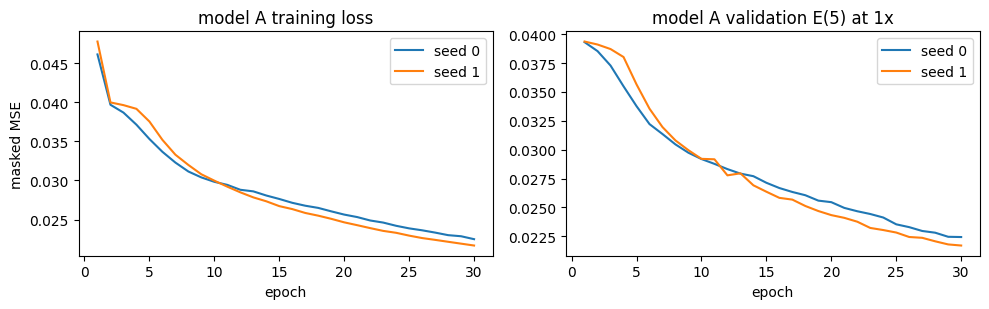

seed 0: mean epoch time 10.7s
seed 1: mean epoch time 10.7s


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for s, h in hists_A.items():
    ax[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label=f"seed {s}")
    ax[1].plot(range(1, len(h["val_E5"]) + 1), h["val_E5"], label=f"seed {s}")
ax[0].set(title="model A training loss", xlabel="epoch", ylabel="masked MSE"); ax[0].legend()
ax[1].set(title="model A validation E(5) at 1x", xlabel="epoch"); ax[1].legend()
fig.tight_layout(); fig.savefig(f"{FIG_DIR}/modelA_curves.png", dpi=130); plt.show()
for s, h in hists_A.items():
    print(f"seed {s}: mean epoch time {np.mean(h['epoch_time']):.1f}s")

## Table 2: Model A vs Blank vs Copy-last (test split, 1×, t = 1)

**What happens:** for each test video and forecast horizon h = 1..5 we compute MSE_h (mean over the 64×64 pixels), then average over the 1,000 test videos.
E⁽⁵⁾ is the mean of the five horizons (handout eq. 5).
Learned models are reported as **mean (seed 0, seed 1)**. Blank and Copy-last are deterministic, so they get one value.

How to read it:
- **Blank** = the error of doing nothing.
- **Copy-last** = the error of assuming nothing moves.

A model that has learned motion should beat Copy-last, especially at later horizons. Model A's error should *grow* with h, because errors compound in the rollout.

*Lecture link:* always compare with a naive repeat-last-value baseline, L5 p.26.

In [7]:
res_A = {s: evaluate(models_A[s], data["test"], return_preds=(s == 0)) for s in (0, 1)}
res_blank = evaluate(Blank(), data["test"])
res_copy = evaluate(CopyLast(), data["test"])

keys = [f"MSE_{h}" for h in range(1, 6)] + ["E5_1x"]
table2 = pd.DataFrame({
    "Model A": {**metrics_row([res_A[0], res_A[1]], keys), "params": f"{count_params(models_A[0]):,}"},
    "Blank": {**metrics_row([res_blank], keys), "params": "0"},
    "Copy-last": {**metrics_row([res_copy], keys), "params": "0"},
}).T.rename(columns={"E5_1x": "E(5)"})
display(table2)
save_table(table2, "table2")
save_json({"A_s0": scalars(res_A[0]), "A_s1": scalars(res_A[1]),
           "Blank": scalars(res_blank), "CopyLast": scalars(res_copy)}, "eval_A_baselines.json")

,MSE_1,MSE_2,MSE_3,MSE_4,MSE_5,E(5),params
Model A,"0.0172 (0.0174, 0.0169)","0.0206 (0.021, 0.0202)","0.0228 (0.0233, 0.0223)","0.0246 (0.025, 0.0241)","0.0262 (0.0267, 0.0258)","0.0223 (0.0227, 0.0219)","480,784"
Blank,0.0426,0.0426,0.0426,0.0425,0.0425,0.0426,0
Copy-last,0.0492,0.0604,0.0669,0.0708,0.0732,0.0641,0


saved /kaggle/working/results/table2.csv / .md
saved /kaggle/working/results/eval_A_baselines.json


## Figure 2: Input, prediction and ground truth for three test videos

**What happens:** we pick three test videos, at least one where the digits **overlap** in the target frames.
`overlapping()` uses a simple heuristic: two separate digits form at least 2 bright blobs, and overlapping digits merge into 1. **Look at the picture** to confirm, and change `chosen` if needed.

What to look for (Q2.4):
- Does the prediction keep the digit's shape and position over h = 1..5, or does it blur?
- When digits overlap, the model can't tell which digit went where. An MSE-trained model then predicts roughly the **average** of the possibilities, which shows up as a smeared or ghosted blob.

*Lecture link:* MSE is minimised by the mean (companion notebook, "Think about 1"); MSE vs MAE, L5 p.12.

586 test videos look overlapping in the targets; 198 look clean
saved /kaggle/working/figures/figure2.png


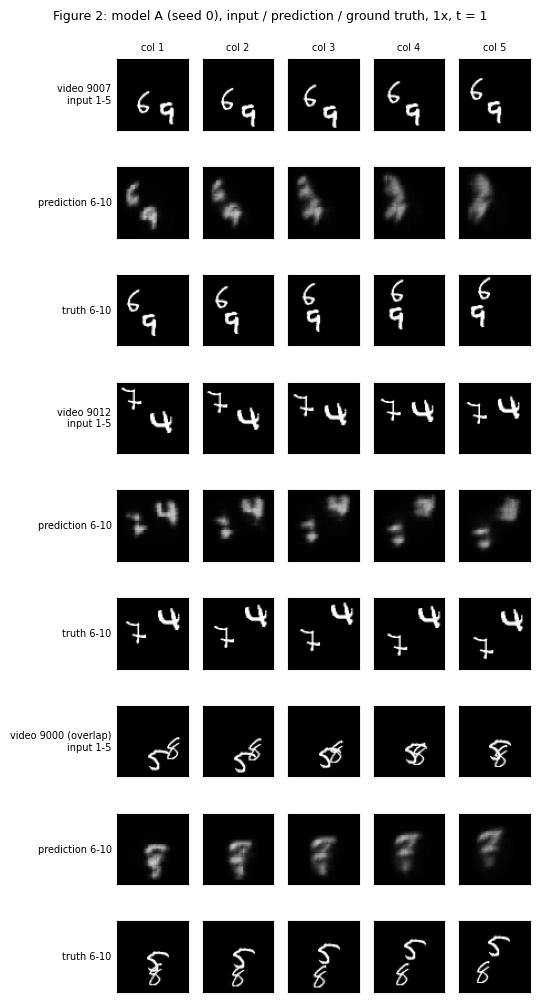

saved /kaggle/working/results/figure2_videos.json


In [8]:
X, Y, P = res_A[0]["preds"]["1x"]
overlap = [i for i in range(len(Y)) if overlapping(Y[i, :, 0])]
clean = [i for i in range(len(Y)) if not overlapping(torch.cat([X[i, :, 0], Y[i, :, 0]]))]
print(f"{len(overlap)} test videos look overlapping in the targets; {len(clean)} look clean")

chosen = [clean[0], clean[1], overlap[0]]   # change these indices after looking, if needed
rows, labels = [], []
for i in chosen:
    tag = " (overlap)" if i in overlap else ""
    rows += [[X[i, j, 0] for j in range(5)], [P[i, j, 0] for j in range(5)], [Y[i, j, 0] for j in range(5)]]
    labels += [f"video {9000 + i}{tag}\ninput 1-5", "prediction 6-10", "truth 6-10"]
plot_grid(rows, labels, [f"col {c}" for c in range(1, 6)],
          title="Figure 2: model A (seed 0), input / prediction / ground truth, 1x, t = 1",
          path=f"{FIG_DIR}/figure2.png")
save_json({"figure2_videos": chosen}, "figure2_videos.json")

## Before you open Notebook 3: write Q2.5 and commit it

The handout requires your **Q2.5 prediction** (will model A pass the mirror test? the rotation test? at what speed does it break?) to be written **before** running any test, and **committed to your GitHub repository** (commit times may be checked).

You now have what you need for it:
- the median speed from Figure 1 (`results/figure1_stats.json`);
- model A's reach (Q2.3);
- Table 2 and Figure 2.

Next: answer Q2.3 and Q2.4, write and commit Q2.5, then run Notebook 3 with **this notebook's output attached as input**, since it needs `ckpt/A_s0.pt` and `ckpt/A_s1.pt`.